# Best Subset Selection with Ridge Regression

In [1]:
# Import the libraries needed for data handling, subset generation, calculations, and plots.
import math
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 1. Load the dataset

In [2]:
# Cell 2: Load the CSV file and show a small preview before doing any modelling.
df = pd.read_csv("YachtHydrodynamics.csv")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")
display(df.head())

Number of rows: 308
Number of columns: 7


,"Longitudinal position of the center of buoyancy, adimensional",Prismatic coefficient,Length-displacement ratio,Beam-draught ratio,Length-beam ratio,Froude number,Residuary resistance per unit weight of displacement
0,-2.3,0.568,4.78,3.99,3.17,0.125,0.11
1,-2.3,0.568,4.78,3.99,3.17,0.150,0.27
2,-2.3,0.568,4.78,3.99,3.17,0.175,0.47
3,-2.3,0.568,4.78,3.99,3.17,0.200,0.78
4,-2.3,0.568,4.78,3.99,3.17,0.225,1.18


## 2. Inspect the data

In [3]:
# Inspect column names, data types, and missing-value counts.

print("Column names:")

for column_number, column_name in enumerate(df.columns, start=1):
    print(f"{column_number}. {column_name}")

Column names:
1. Longitudinal position of the center of buoyancy, adimensional
2. Prismatic coefficient
3. Length-displacement ratio
4. Beam-draught ratio
5. Length-beam ratio
6. Froude number
7. Residuary resistance per unit weight of displacement


## 3. Separate predictors and response

In [4]:
# Split the dataframe into predictor matrix X and response vector y.
feature_names = list(df.columns[:-1])
target_name = df.columns[-1]

X = df.iloc[:, :-1].to_numpy(dtype=float)
y = df.iloc[:, -1].to_numpy(dtype=float)

print("Predictor matrix X shape:", X.shape)
print("Response vector y shape:", y.shape)
print("Target column:", target_name)
print("Number of candidate predictors:", len(feature_names))
print("\nTarget summary statistics:")
print(pd.Series(y, name=target_name).describe())

Predictor matrix X shape: (308, 6)
Response vector y shape: (308,)
Target column: Residuary resistance per unit weight of displacement
Number of candidate predictors: 6

Target summary statistics:
count    308.000000
mean      10.495357
std       15.160490
min        0.010000
25%        0.777500
50%        3.065000
75%       12.815000
max       62.420000
Name: Residuary resistance per unit weight of displacement, dtype: float64


## 4. Define the ridge-regression RSS function

In [5]:
RIDGE_ALPHA = 0.001  # Regularization strength used in the original notebook.


def ridge_regression_rss(X_subset, y, alpha=RIDGE_ALPHA):
    # Convert a feature subset to a 2-D matrix, including when the subset is empty.
    X_subset = np.asarray(X_subset, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)

    if X_subset.ndim != 2:
        raise ValueError("X_subset must be a two-dimensional array.")

    if X_subset.shape[0] != y.shape[0]:
        raise ValueError("X_subset and y must contain the same number of rows.")

    # Add an intercept column so that the model can learn a constant offset.
    X_design = np.column_stack((np.ones(X_subset.shape[0]), X_subset))

    # Penalize feature coefficients only; leave the intercept unpenalized.
    penalty_matrix = np.eye(X_design.shape[1])
    penalty_matrix[0, 0] = 0.0

    # Solve (X'X + alpha * P) beta = X'y for the ridge coefficients.
    system_matrix = X_design.T @ X_design + alpha * penalty_matrix
    right_hand_side = X_design.T @ y
    coefficients = np.linalg.solve(system_matrix, right_hand_side)

    # Calculate predictions and their residual sum of squares.
    y_predicted = X_design @ coefficients
    rss = np.sum((y - y_predicted) ** 2)
    return float(rss)


print(f"Ridge RSS function is ready (alpha = {RIDGE_ALPHA}).")


Ridge RSS function is ready (alpha = 0.001).


## 5. Enumerate feature subsets

In [6]:
# Find the lowest-RSS subset for every model size, from zero features to all features.
p = X.shape[1]
all_feature_indices = range(p)
best_models = []

for subset_size in range(p + 1):
    # Evaluate every combination containing exactly subset_size predictors.
    subset_results = []

    for subset in combinations(all_feature_indices, subset_size):
        X_subset = X[:, subset]
        rss = ridge_regression_rss(X_subset, y)
        subset_results.append((subset, rss))

    # Keep only the subset with the minimum RSS for this model size.
    best_subset, best_rss = min(subset_results, key=lambda result: result[1])
    best_models.append({
        "model_size": subset_size,
        "subset": best_subset,
        "rss": best_rss,
    })
    selected_names = [feature_names[index] for index in best_subset]
    print(f"Model size {subset_size}: RSS = {best_rss:.6f}")
    print("  Selected predictors:", ", ".join(selected_names) if selected_names else "(intercept only)")


Model size 0: RSS = 70561.021261
  Selected predictors: (intercept only)
Model size 1: RSS = 24255.397307
  Selected predictors: Froude number
Model size 2: RSS = 24197.807833
  Selected predictors: Prismatic coefficient, Froude number
Model size 3: RSS = 24172.171786
  Selected predictors: Longitudinal position of the center of buoyancy, adimensional, Prismatic coefficient, Froude number
Model size 4: RSS = 24170.905355
  Selected predictors: Longitudinal position of the center of buoyancy, adimensional, Prismatic coefficient, Length-displacement ratio, Froude number
Model size 5: RSS = 24164.346947
  Selected predictors: Longitudinal position of the center of buoyancy, adimensional, Length-displacement ratio, Beam-draught ratio, Length-beam ratio, Froude number
Model size 6: RSS = 24162.650846
  Selected predictors: Longitudinal position of the center of buoyancy, adimensional, Prismatic coefficient, Length-displacement ratio, Beam-draught ratio, Length-beam ratio, Froude number


## 6. Compare the best subset at each model size

In [7]:
# Create a readable results table showing the best subset for each model size.
subset_results_df = pd.DataFrame([
    {
        "Number of Predictors": model["model_size"],
        "Selected Predictors": (
            ", ".join(feature_names[index] for index in model["subset"])
            if model["subset"] else "(intercept only)"
        ),
        "RSS": model["rss"],
    }
    for model in best_models
])

print("Best subset for each model size:")
display(subset_results_df.round({"RSS": 6}))

Best subset for each model size:


,Number of Predictors,Selected Predictors,RSS
0,0,(intercept only),70561.021261
1,1,Froude number,24255.397307
2,2,"Prismatic coefficient, Froude number",24197.807833
3,3,Longitudinal position of the center of buoyanc...,24172.171786
4,4,Longitudinal position of the center of buoyanc...,24170.905355
5,5,Longitudinal position of the center of buoyanc...,24164.346947
6,6,Longitudinal position of the center of buoyanc...,24162.650846


## 7. Calculate AIC for the candidate models

In [8]:
# Calculate an AIC approximation for every best-by-size model.
n = len(y)
aic_results = []

for model in best_models:
    rss = max(model["rss"], np.finfo(float).tiny)  # Protect the logarithm from a zero RSS.
    parameter_count = 1 + model["model_size"]  # One intercept plus the selected predictors.
    aic = n * math.log(rss / n) + 2 * parameter_count
    aic_results.append({
        "model_size": model["model_size"],
        "subset": model["subset"],
        "rss": model["rss"],
        "parameter_count": parameter_count,
        "aic": aic,
    })

# Display every candidate model's RSS and AIC so the selection can be checked.
aic_results_df = pd.DataFrame([
    {
        "Number of Predictors": result["model_size"],
        "Selected Predictors": (
            ", ".join(feature_names[index] for index in result["subset"])
            if result["subset"] else "(intercept only)"
        ),
        "RSS": result["rss"],
        "Parameter Count": result["parameter_count"],
        "AIC": result["aic"],
    }
    for result in aic_results
])

display(aic_results_df.round({"RSS": 6, "AIC": 4}))


,Number of Predictors,Selected Predictors,RSS,Parameter Count,AIC
0,0,(intercept only),70561.021261,1,1675.7131
1,1,Froude number,24255.397307,2,1348.8188
2,2,"Prismatic coefficient, Froude number",24197.807833,3,1350.0866
3,3,Longitudinal position of the center of buoyanc...,24172.171786,4,1351.7601
4,4,Longitudinal position of the center of buoyanc...,24170.905355,5,1353.7440
5,5,Longitudinal position of the center of buoyanc...,24164.346947,6,1355.6604
6,6,Longitudinal position of the center of buoyanc...,24162.650846,7,1357.6388


## 8. Select the model with the lowest AIC

In [9]:
# Identify and report the lowest-AIC candidate model.
best_aic_model = min(aic_results, key=lambda result: result["aic"])
best_feature_names = [feature_names[index] for index in best_aic_model["subset"]]

print("Best model according to the AIC approximation")
print("------------------------------------------------")
print("Number of predictors:", best_aic_model["model_size"])
print("Selected predictors:", ", ".join(best_feature_names) if best_feature_names else "(intercept only)")
print(f"RSS: {best_aic_model['rss']:.6f}")
print(f"AIC: {best_aic_model['aic']:.4f}")


Best model according to the AIC approximation
------------------------------------------------
Number of predictors: 1
Selected predictors: Froude number
RSS: 24255.397307
AIC: 1348.8188


## 9. Visualize RSS and AIC

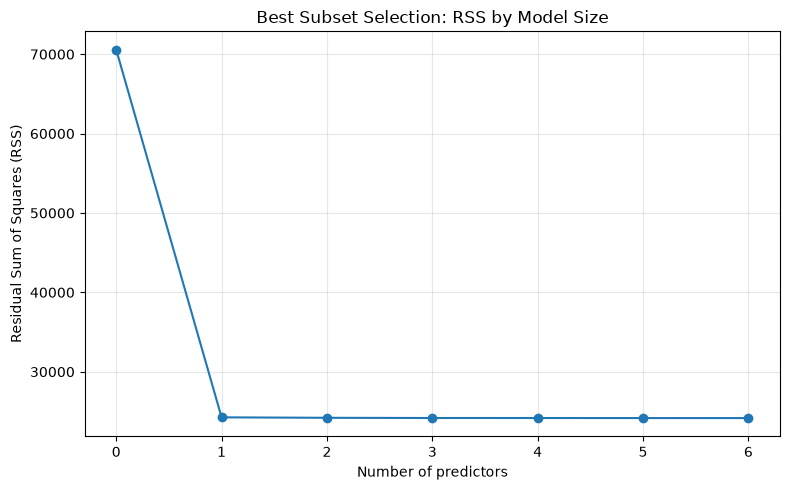

In [10]:
# Plot RSS against the number of selected predictors.
model_sizes = [model["model_size"] for model in best_models]
rss_values = [model["rss"] for model in best_models]

plt.figure(figsize=(8, 5))
plt.plot(model_sizes, rss_values, marker="o")
plt.xlabel("Number of predictors")
plt.ylabel("Residual Sum of Squares (RSS)")
plt.title("Best Subset Selection: RSS by Model Size")
plt.xticks(model_sizes)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


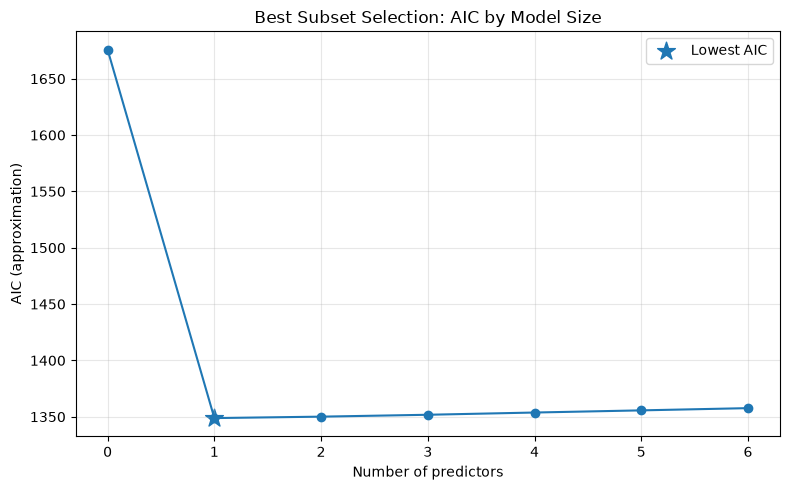

In [11]:
# Plot AIC against the number of predictors and mark the selected model.
aic_values = [result["aic"] for result in aic_results]
best_size = best_aic_model["model_size"]

plt.figure(figsize=(8, 5))
plt.plot(model_sizes, aic_values, marker="o")
plt.scatter(
    [best_size], [best_aic_model["aic"]],
    marker="*", s=180, label="Lowest AIC"
)
plt.xlabel("Number of predictors")
plt.ylabel("AIC (approximation)")
plt.title("Best Subset Selection: AIC by Model Size")
plt.xticks(model_sizes)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()